# OrganMNIST3D: entrenamiento 2.5D vs 3D (Kaggle)

Corrida completa del protocolo del artículo (Tablas 8 y 9): ResNet 2.5D y ResNet 3D, 100 épocas,
semillas 0, 1 y 2, Adam 1e-3 con coseno, lote 32, pérdida ponderada y selección por F1 macro en validación.

**Antes de ejecutar**
1. *Settings → Accelerator → GPU T4 x2* (el script usa una sola T4, como dice la Tabla 8).
2. *Settings → Internet → On*: el notebook descarga OrganMNIST3D con el paquete oficial `medmnist` desde Zenodo
   (la fuente citada en las entregas: MedMNIST v2, CC BY 4.0) y verifica el MD5.
   Solo si no tienes Internet: *Add Input → Upload* con `organmnist3d.npz`.
3. *Save Version → Save & Run All (Commit)*: corre en segundo plano y los archivos quedan en la pestaña *Output*.

La celda del script es una copia exacta de `organmnist3d_completo.py`.

In [1]:
EPOCAS = 100          # 1 para una prueba rápida
SEMILLAS = [0, 1, 2]

In [2]:
%%writefile organmnist3d_completo.py
"""OrganMNIST3D: manejo de datos y comparación 2.5D vs 3D (un solo archivo).

Uso:
    pip install medmnist torch numpy scikit-learn matplotlib pandas
    python organmnist3d_completo.py                      # descarga OrganMNIST3D y entrena (100 épocas, 3 semillas)
    python organmnist3d_completo.py --epocas 5 --semillas 0   # prueba rápida
    python organmnist3d_completo.py --npz ruta/organmnist3d.npz  # si ya tienes el archivo

Genera: fig_distribucion_clases.png, fig_muestra_cortes.png, fig_confusion_3d.png, resultados.csv
"""
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

CLASES = ["liver", "kidney-right", "kidney-left", "femur-right", "femur-left", "bladder",
          "heart", "lung-right", "lung-left", "spleen", "pancreas"]
N_CLASES = 11


# ------------------------------------------------------------------ carga y resumen
def cargar_npz(ruta):
    """Lee el .npz de MedMNIST. Devuelve dict con train/val/test -> (X uint8 [N,28,28,28], y int64 [N])."""
    d = np.load(ruta)
    out = {}
    for s in ("train", "val", "test"):
        X, y = d[f"{s}_images"], d[f"{s}_labels"].reshape(-1).astype(np.int64)
        assert X.ndim == 4 and X.shape[1:] == (28, 28, 28), X.shape
        out[s] = (X, y)
    return out


def resumen(datos):
    for s, (X, y) in datos.items():
        cnt = np.bincount(y, minlength=N_CLASES)
        print(f"{s:5s} X={X.shape} dtype={X.dtype} min={X.min()} max={X.max()} | por clase: {cnt.tolist()}")


# ------------------------------------------------------------------ preprocesamiento
def estadisticas_train(X):
    """Media y desviación calculadas SOLO con entrenamiento (evita fuga de datos)."""
    x = X.astype(np.float32) / 255.0
    return float(x.mean()), float(x.std() + 1e-8)


class Organ3D(Dataset):
    """Representación 3D: tensor (1, 28, 28, 28)  |  modo '2.5d': la profundidad pasa a canales (28, 28, 28)."""

    def __init__(self, X, y, media, desv, modo="3d", aumento=False, seed=0):
        self.X, self.y, self.m, self.s, self.modo, self.aug = X, y, media, desv, modo, aumento
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return len(self.y)

    def _aumentar(self, v):
        # Sin volteos: izquierda/derecha cambian la clase (kidney-left vs kidney-right, etc.).
        sh = self.rng.integers(-2, 3, size=3)                       # traslación de hasta 2 vóxeles
        v = np.roll(v, shift=tuple(sh), axis=(0, 1, 2))
        v = v * self.rng.uniform(0.9, 1.1) + self.rng.uniform(-0.05, 0.05)   # contraste y brillo
        v = v + self.rng.normal(0, 0.01, v.shape).astype(np.float32)        # ruido gaussiano suave
        return v

    def __getitem__(self, i):
        v = self.X[i].astype(np.float32) / 255.0
        if self.aug:
            v = self._aumentar(v)
        v = (v - self.m) / self.s
        t = torch.from_numpy(np.ascontiguousarray(v))
        t = t.unsqueeze(0) if self.modo == "3d" else t              # (1,D,H,W) o (D,H,W)=canales
        return t, int(self.y[i])


def pesos_clase(y):
    """Pesos inversamente proporcionales a la frecuencia (para la pérdida ponderada)."""
    cnt = np.bincount(y, minlength=N_CLASES).astype(np.float32)
    w = cnt.sum() / (N_CLASES * np.maximum(cnt, 1))
    return torch.tensor(w)


def loaders(datos, modo="3d", batch=32, seed=0):
    m, s = estadisticas_train(datos["train"][0])
    ds = {k: Organ3D(*datos[k], m, s, modo, aumento=(k == "train"), seed=seed) for k in datos}
    g = torch.Generator().manual_seed(seed)
    return {k: DataLoader(ds[k], batch_size=batch, shuffle=(k == "train"), generator=g if k == "train" else None)
            for k in ds}


# ------------------------------------------------------------------ modelos
class Bloque(nn.Module):
    def __init__(self, cin, cout, stride, dim):
        super().__init__()
        Conv, BN = (nn.Conv3d, nn.BatchNorm3d) if dim == 3 else (nn.Conv2d, nn.BatchNorm2d)
        self.c1 = Conv(cin, cout, 3, stride, 1, bias=False); self.b1 = BN(cout)
        self.c2 = Conv(cout, cout, 3, 1, 1, bias=False); self.b2 = BN(cout)
        self.sc = None if (stride == 1 and cin == cout) else nn.Sequential(Conv(cin, cout, 1, stride, bias=False), BN(cout))

    def forward(self, x):
        o = F.relu(self.b1(self.c1(x)))
        o = self.b2(self.c2(o))
        return F.relu(o + (x if self.sc is None else self.sc(x)))


class ResNetPequena(nn.Module):
    """ResNet con 4 etapas de 2 bloques. dim=3 (volumétrica) o dim=2 (2.5D, profundidad como canales)."""

    def __init__(self, dim, cin, anchos, n_clases=N_CLASES):
        super().__init__()
        Conv, BN = (nn.Conv3d, nn.BatchNorm3d) if dim == 3 else (nn.Conv2d, nn.BatchNorm2d)
        self.dim = dim
        self.stem = nn.Sequential(Conv(cin, anchos[0], 3, 1, 1, bias=False), BN(anchos[0]), nn.ReLU(inplace=True))
        capas, c = [], anchos[0]
        for i, a in enumerate(anchos):
            capas += [Bloque(c, a, 1 if i == 0 else 2, dim), Bloque(a, a, 1, dim)]
            c = a
        self.capas = nn.Sequential(*capas)
        self.fc = nn.Linear(c, n_clases)

    def forward(self, x):
        x = self.capas(self.stem(x))
        x = x.mean(dim=(2, 3, 4) if self.dim == 3 else (2, 3))
        return self.fc(x)


def modelo(modo, anchos=None):
    if modo == "3d":
        return ResNetPequena(3, 1, anchos or (16, 32, 64, 128))
    return ResNetPequena(2, 28, anchos or (28, 56, 112, 224))


def n_param(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


# ------------------------------------------------------------------ entrenamiento y métricas
@torch.no_grad()
def predecir(m, dl, dev):
    m.eval(); P, Y = [], []
    for x, y in dl:
        P.append(F.softmax(m(x.to(dev)), 1).cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()


def metricas(P, Y):
    from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
    pred = P.argmax(1)
    try:
        auc = roc_auc_score(Y, P, multi_class="ovr", average="macro", labels=list(range(N_CLASES)))
    except ValueError:
        auc = float("nan")
    return {"acc": accuracy_score(Y, pred), "f1_macro": f1_score(Y, pred, average="macro"),
            "auc_ovr": auc, "cm": confusion_matrix(Y, pred, labels=list(range(N_CLASES)))}


def entrenar(modo, datos, epocas=50, lr=1e-3, batch=32, seed=0, ponderar=True, dev=None, verbose=True):
    torch.manual_seed(seed); np.random.seed(seed)
    dev = dev or ("cuda" if torch.cuda.is_available() else "cpu")
    dl = loaders(datos, modo, batch, seed)
    m = modelo(modo).to(dev)
    w = pesos_clase(datos["train"][1]).to(dev) if ponderar else None
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epocas)
    mejor, estado = -1, None
    for ep in range(epocas):
        m.train()
        for x, y in dl["train"]:
            x, y = x.to(dev), y.to(dev)
            loss = F.cross_entropy(m(x), y, weight=w)
            opt.zero_grad(); loss.backward(); opt.step()
        sch.step()
        r = metricas(*predecir(m, dl["val"], dev))
        if r["f1_macro"] > mejor:
            mejor, estado = r["f1_macro"], {k: v.clone() for k, v in m.state_dict().items()}
        if verbose:
            print(f"{modo} seed {seed} ep {ep+1:3d} loss {loss.item():.3f} val acc {r['acc']:.3f} F1 {r['f1_macro']:.3f}", flush=True)
    m.load_state_dict(estado)
    return m, metricas(*predecir(m, dl["test"], dev))


def figura_predicciones(m, datos, modo="3d", n=12, archivo="fig_predicciones_3d.png"):
    """Cortes centrales de muestras de prueba con la clase verdadera y la predicha por el modelo."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    dev = next(m.parameters()).device
    dl = loaders(datos, modo, 64)
    P, Y = predecir(m, dl["test"], dev)
    pred = P.argmax(1)
    rng = np.random.default_rng(0)
    idx = np.concatenate([rng.choice(np.where(Y == c)[0], 1) for c in range(N_CLASES)])   # una por clase
    X = datos["test"][0]
    fig, ax = plt.subplots(2, 6, figsize=(12, 4.4))
    for a, i in zip(ax.ravel(), idx):
        a.imshow(X[i][14], cmap="gray"); a.axis("off")
        ok = pred[i] == Y[i]
        a.set_title(f"real: {CLASES[Y[i]]}\npred: {CLASES[pred[i]]}", fontsize=7, color="green" if ok else "red")
    for a in ax.ravel()[len(idx):]:
        a.axis("off")
    plt.tight_layout(); plt.savefig(archivo, dpi=200); plt.close()


def reporte_por_clase(cm, archivo="metricas_por_clase.csv"):
    import pandas as pd
    tp = np.diag(cm).astype(float); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    prec = tp / np.maximum(tp + fp, 1); rec = tp / np.maximum(tp + fn, 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
    iou = tp / np.maximum(tp + fp + fn, 1)
    pd.DataFrame({"clase": CLASES, "soporte": cm.sum(1), "precision": prec, "recall": rec, "f1": f1, "iou": iou}).round(3).to_csv(archivo, index=False)


# ------------------------------------------------------------------ programa principal
def obtener_ruta(npz):
    if npz:
        return npz
    import os
    from medmnist import OrganMNIST3D
    OrganMNIST3D(split="train", download=True, size=28)   # guarda ~/.medmnist/organmnist3d.npz
    return os.path.expanduser("~/.medmnist/organmnist3d.npz")


def graficas(datos):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    cnt = {s: np.bincount(datos[s][1], minlength=N_CLASES) for s in datos}
    x, w = np.arange(N_CLASES), 0.28
    plt.figure(figsize=(9, 3.2))
    for i, s in enumerate(("train", "val", "test")):
        plt.bar(x + (i - 1) * w, cnt[s], w, label=s)
    plt.xticks(x, CLASES, rotation=45, ha="right"); plt.ylabel("volúmenes"); plt.legend(); plt.tight_layout()
    plt.savefig("fig_distribucion_clases.png", dpi=200); plt.close()

    X, y = datos["train"]
    fig, ax = plt.subplots(3, N_CLASES, figsize=(14, 4.2))
    for c in range(N_CLASES):
        idx = np.where(y == c)[0]
        if len(idx) == 0:
            continue
        v = X[idx[0]]
        for r, sl in enumerate((v[14, :, :], v[:, 14, :], v[:, :, 14])):
            ax[r, c].imshow(sl, cmap="gray"); ax[r, c].axis("off")
        ax[0, c].set_title(CLASES[c], fontsize=7)
    plt.tight_layout(); plt.savefig("fig_muestra_cortes.png", dpi=200); plt.close()


def main():
    import argparse, time
    import pandas as pd
    ap = argparse.ArgumentParser()
    ap.add_argument("--npz", default=None, help="ruta a organmnist3d.npz (si no, se descarga)")
    ap.add_argument("--epocas", type=int, default=100)
    ap.add_argument("--semillas", type=int, nargs="+", default=[0, 1, 2])
    ap.add_argument("--batch", type=int, default=32)
    a = ap.parse_args()

    datos = cargar_npz(obtener_ruta(a.npz))
    resumen(datos)
    graficas(datos)
    for modo in ("3d", "2.5d"):
        x, _ = next(iter(loaders(datos, modo, a.batch)["train"]))
        print(modo, "lote:", tuple(x.shape), "| parámetros:", n_param(modelo(modo)))

    filas, cms, modelos = [], {}, {}
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    for modo in ("2.5d", "3d"):
        for seed in a.semillas:
            if dev == "cuda":
                torch.cuda.reset_peak_memory_stats()
            t = time.time()
            m, r = entrenar(modo, datos, epocas=a.epocas, batch=a.batch, seed=seed, verbose=True)
            modelos[(modo, seed)] = m
            fila = dict(modo=modo, seed=seed, acc=r["acc"], f1_macro=r["f1_macro"], auc_ovr=r["auc_ovr"],
                        s_por_epoca=(time.time() - t) / a.epocas)
            if dev == "cuda":
                fila["mem_gpu_gb"] = torch.cuda.max_memory_allocated() / 1e9
            filas.append(fila); cms[(modo, seed)] = r["cm"]
            print(fila)
    df = pd.DataFrame(filas)
    df.to_csv("resultados.csv", index=False)
    np.savez("matrices_confusion.npz", **{f"{k[0]}_seed{k[1]}": v for k, v in cms.items()})
    print(df.groupby("modo").agg(["mean", "std"]).round(3).to_string())

    import matplotlib.pyplot as plt
    figura_predicciones(modelos[("3d", a.semillas[0])], datos, "3d", archivo="fig_predicciones_3d.png")
    figura_predicciones(modelos[("2.5d", a.semillas[0])], datos, "2.5d", archivo="fig_predicciones_2_5d.png")
    for k, v in cms.items():
        reporte_por_clase(v, f"metricas_por_clase_{k[0]}_seed{k[1]}.csv")
    cm = cms[("3d", a.semillas[0])]
    plt.figure(figsize=(6, 5)); plt.imshow(cm / np.maximum(cm.sum(1, keepdims=True), 1), cmap="Blues")
    plt.xticks(range(N_CLASES), CLASES, rotation=60, ha="right", fontsize=7); plt.yticks(range(N_CLASES), CLASES, fontsize=7)
    plt.colorbar(); plt.tight_layout(); plt.savefig("fig_confusion_3d.png", dpi=200); plt.close()


if __name__ == "__main__":
    main()

Writing organmnist3d_completo.py


## 1. Entorno (para la Tabla 8)

In [3]:
import platform, numpy, sklearn, torch

info = [f"python {platform.python_version()}", f"torch {torch.__version__}", f"cuda {torch.version.cuda}",
        f"numpy {numpy.__version__}", f"scikit-learn {sklearn.__version__}"]
if torch.cuda.is_available():
    info.append(f"gpu {torch.cuda.get_device_name(0)} ({torch.cuda.device_count()} visibles)")
else:
    info.append("gpu ninguna")
    print("AVISO: no hay GPU. Activa Settings → Accelerator → GPU T4 x2 o el 3D tardará horas.")
open("entorno.txt", "w", encoding="utf-8").write("\n".join(info) + "\n")
print("\n".join(info))

python 3.13.15
torch 2.11.0+cu128
cuda 12.8
numpy 2.1.3
scikit-learn 1.6.1
gpu Tesla T4 (2 visibles)


## 2. Dataset

In [4]:
import glob, hashlib, os, subprocess, sys

MD5_OFICIAL = "a0c5a1ff56af4f155c46d46fbb45a2fe"   # INFO["organmnist3d"]["MD5"] en medmnist 3.0.2
RAIZ = os.environ.get("ORGANMNIST3D_RAIZ", os.path.expanduser("~/.medmnist"))


def md5(ruta):
    h = hashlib.md5()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()


# Fuente oficial (primer avance, 3.1): paquete medmnist, que descarga de Zenodo.
try:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "medmnist"], check=True)
    import medmnist
    from medmnist import INFO, OrganMNIST3D
    os.makedirs(RAIZ, exist_ok=True)
    OrganMNIST3D(split="train", download=True, size=28, root=RAIZ)
    ruta = os.path.join(RAIZ, "organmnist3d.npz")
    fuente = f"medmnist {medmnist.__version__}: {INFO['organmnist3d']['url']}"
except Exception as e:
    print("No se pudo descargar con medmnist (¿Internet apagado?):", e)
    ruta = next(iter(glob.glob("/kaggle/input/**/organmnist3d.npz", recursive=True)), None)
    assert ruta, "Activa Settings → Internet → On (o adjunta organmnist3d.npz como input)."
    fuente = f"archivo adjunto: {ruta}"

suma = md5(ruta)
assert suma == MD5_OFICIAL, f"MD5 {suma} no coincide con el oficial {MD5_OFICIAL}"
with open("entorno.txt", "a", encoding="utf-8") as f:
    f.write(f"dataset {fuente}\ndataset md5 {suma} (coincide con el oficial)\n")
print("dataset:", ruta)
print("fuente:", fuente)
print("md5:", suma, "OK")

100%|██████████| 32.7M/32.7M [00:34<00:00, 941kB/s] 


dataset: /root/.medmnist/organmnist3d.npz
fuente: medmnist 3.0.2: https://zenodo.org/records/10519652/files/organmnist3d.npz?download=1
md5: a0c5a1ff56af4f155c46d46fbb45a2fe OK


## 3. Entrenamiento (2.5D y 3D, todas las semillas)

In [5]:
cmd = [sys.executable, "-u", "organmnist3d_completo.py", "--epocas", str(EPOCAS),
       "--semillas", *map(str, SEMILLAS), "--npz", ruta]
env = dict(os.environ, PYTHONIOENCODING="utf-8")
with open("entrenamiento.log", "w", encoding="utf-8") as log, \
        subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, encoding="utf-8", env=env) as p:
    for linea in p.stdout:
        print(linea, end="")
        log.write(linea)
assert p.returncode == 0, f"el entrenamiento falló (código {p.returncode}); revisa entrenamiento.log"

train X=(971, 28, 28, 28) dtype=uint8 min=0 max=255 | por clase: [115, 115, 115, 91, 93, 94, 40, 39, 39, 115, 115]
val   X=(161, 28, 28, 28) dtype=uint8 min=0 max=255 | por clase: [16, 16, 14, 14, 15, 15, 13, 13, 13, 16, 16]
test  X=(610, 28, 28, 28) dtype=uint8 min=0 max=255 | por clase: [69, 68, 69, 65, 65, 66, 28, 21, 21, 69, 69]
3d lote: (32, 1, 28, 28, 28) | parámetros: 2074779
2.5d lote: (32, 28, 28, 28) | parámetros: 2149347
2.5d seed 0 ep   1 loss 1.446 val acc 0.565 F1 0.522
2.5d seed 0 ep   2 loss 0.785 val acc 0.764 F1 0.756
2.5d seed 0 ep   3 loss 1.342 val acc 0.913 F1 0.916
2.5d seed 0 ep   4 loss 0.546 val acc 0.938 F1 0.940
2.5d seed 0 ep   5 loss 0.603 val acc 0.882 F1 0.886
2.5d seed 0 ep   6 loss 0.217 val acc 0.901 F1 0.906
2.5d seed 0 ep   7 loss 0.800 val acc 0.963 F1 0.962
2.5d seed 0 ep   8 loss 0.453 val acc 0.938 F1 0.940
2.5d seed 0 ep   9 loss 0.459 val acc 0.932 F1 0.927
2.5d seed 0 ep  10 loss 1.026 val acc 0.963 F1 0.964
2.5d seed 0 ep  11 loss 0.114 val 

## 4. Resultados y descarga

,modo,seed,acc,f1_macro,auc_ovr,s_por_epoca,mem_gpu_gb
0,2.5d,0,0.859016,0.880045,0.990562,0.915208,0.131012
1,2.5d,1,0.922951,0.936039,0.996731,0.872104,0.147926
2,2.5d,2,0.886885,0.902788,0.993319,0.871143,0.167501
3,3d,0,0.890164,0.901499,0.994520,7.221277,0.711156
4,3d,1,0.936066,0.946029,0.998674,7.222035,0.729053
5,3d,2,0.909836,0.917196,0.995876,7.222994,0.746037


acc        f1_macro        auc_ovr        s_por_epoca         \
       mean    std     mean    std    mean    std        mean    std   
modo                                                                   
2.5d  0.890  0.032    0.906  0.028   0.994  0.003       0.886  0.025   
3d    0.912  0.023    0.922  0.023   0.996  0.002       7.222  0.001   

     mem_gpu_gb         
           mean    std  
modo                    
2.5d      0.149  0.018  
3d        0.729  0.017

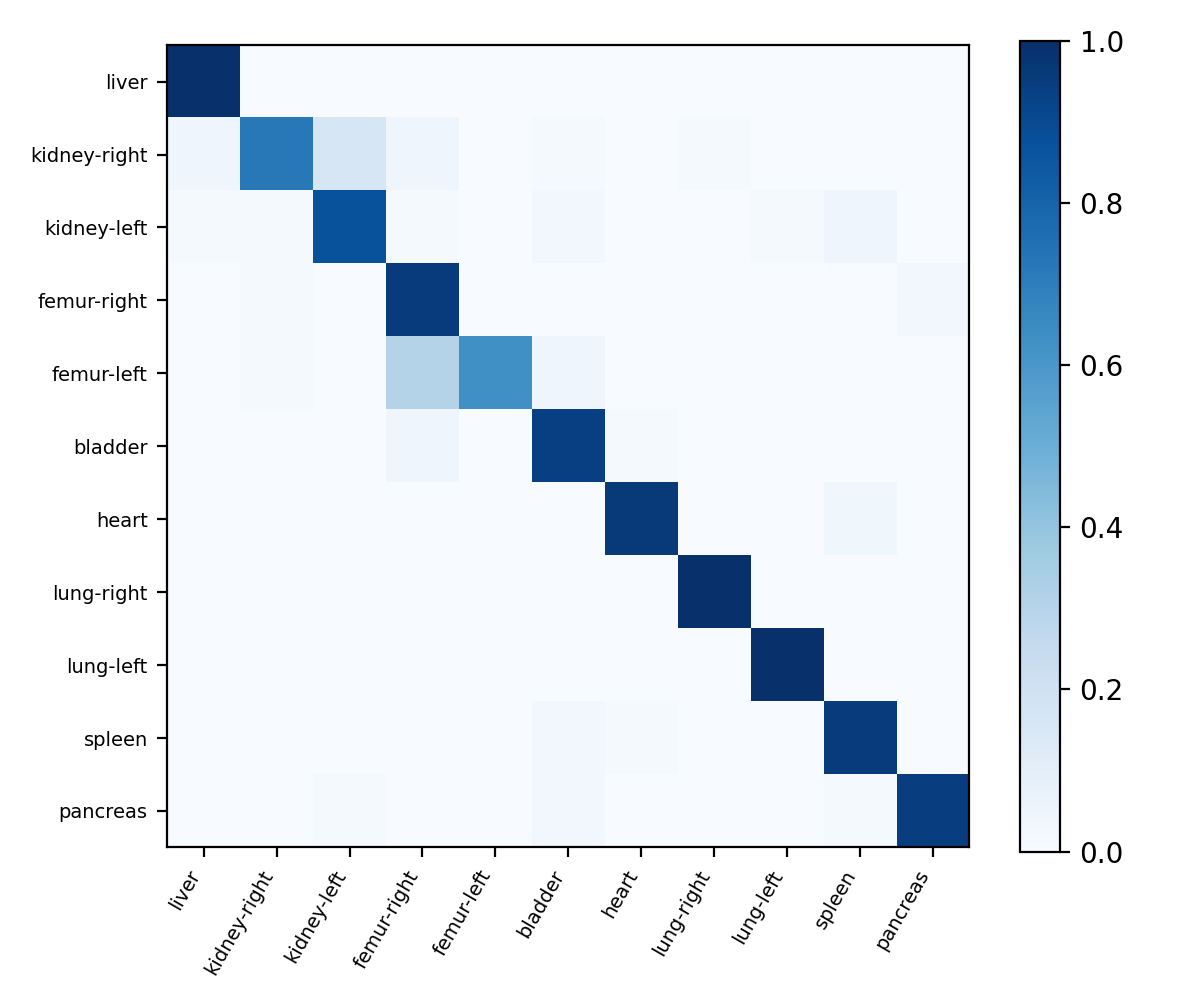

Empaquetado en resultados_organmnist3d.zip: fig_confusion_3d.png, fig_distribucion_clases.png, fig_muestra_cortes.png, fig_predicciones_2_5d.png, fig_predicciones_3d.png, metricas_por_clase_2.5d_seed0.csv, metricas_por_clase_2.5d_seed1.csv, metricas_por_clase_2.5d_seed2.csv, metricas_por_clase_3d_seed0.csv, metricas_por_clase_3d_seed1.csv, metricas_por_clase_3d_seed2.csv, resultados.csv, matrices_confusion.npz, entrenamiento.log, entorno.txt


In [6]:
import zipfile
import pandas as pd
from IPython.display import Image, display

df = pd.read_csv("resultados.csv")
display(df)
display(df.drop(columns="seed").groupby("modo").agg(["mean", "std"]).round(3))
display(Image("fig_confusion_3d.png", width=480))

salidas = sorted(glob.glob("fig_*.png") + glob.glob("*.csv")) + ["matrices_confusion.npz", "entrenamiento.log", "entorno.txt"]
with zipfile.ZipFile("resultados_organmnist3d.zip", "w") as z:
    for f in salidas:
        z.write(f)
print("Empaquetado en resultados_organmnist3d.zip:", ", ".join(salidas))